# 01 — Data Exploration

**Progetto:** Super-Resolution su LSUN Church  
**Obiettivo:** Esplorare il dataset, verificare il preprocessing (resize, normalizzazione, split) e visualizzare esempi di degradazione.

---

In [19]:
import sys
import os
sys.path.insert(0, os.path.join('..', 'src'))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
from pathlib import Path
import torch

from normalization import default_normalizer, ImageNormalizer
from degradations import DegradationOperator

print('Imports OK')
print(f'PyTorch version: {torch.__version__}')

Imports OK
PyTorch version: 2.11.0+cu130


## 1. Verifica struttura del dataset

Se il dataset non è ancora stato scaricato, esegui prima:
```bash
python src/dataset.py
```

In [20]:
data_dir = Path('..') / 'data'

splits = ['train', 'val', 'test']
print('=== Struttura Dataset ===')
for split in splits:
    split_dir = data_dir / split
    if split_dir.exists():
        files = list(split_dir.glob('*.png')) + list(split_dir.glob('*.jpg'))
        print(f'  {split:6s}: {len(files):5d} immagini — {split_dir}')
    else:
        print(f'  {split:6s}: DIRECTORY NON TROVATA — esegui src/dataset.py')

total = sum(
    len(list((data_dir / s).glob('*.png')) + list((data_dir / s).glob('*.jpg')))
    for s in splits if (data_dir / s).exists()
)
print(f'\n  TOTALE: {total} immagini')
print(f'  Split atteso: Train 80% ({int(4000*0.8)}), Val 10% ({int(4000*0.1)}), Test 10% ({int(4000*0.1)})')

=== Struttura Dataset ===
  train :  3200 immagini — ../data/train
  val   :   400 immagini — ../data/val
  test  :   400 immagini — ../data/test

  TOTALE: 4000 immagini
  Split atteso: Train 80% (3200), Val 10% (400), Test 10% (400)


## 2. Analisi dimensioni e formato immagini

In [21]:
# Analizza un campione di immagini dal training set
train_dir = data_dir / 'train'

if train_dir.exists():
    sample_files = sorted(train_dir.glob('*.png'))[:10]
    sizes = []
    modes = []
    for f in sample_files:
        img = Image.open(f)
        sizes.append(img.size)
        modes.append(img.mode)
    
    print('Campione di 10 immagini dal training set:')
    for f, s, m in zip(sample_files, sizes, modes):
        print(f'  {f.name}: size={s}, mode={m}')
    
    unique_sizes = set(sizes)
    unique_modes = set(modes)
    print(f'\nDimensioni uniche: {unique_sizes}')
    print(f'Modi unici: {unique_modes}')
else:
    print('Dataset non trovato. Esegui prima src/dataset.py')

Campione di 10 immagini dal training set:
  church_0000.png: size=(256, 256), mode=RGB
  church_0002.png: size=(256, 256), mode=RGB
  church_0003.png: size=(256, 256), mode=RGB
  church_0005.png: size=(256, 256), mode=RGB
  church_0006.png: size=(256, 256), mode=RGB
  church_0007.png: size=(256, 256), mode=RGB
  church_0008.png: size=(256, 256), mode=RGB
  church_0009.png: size=(256, 256), mode=RGB
  church_0010.png: size=(256, 256), mode=RGB
  church_0012.png: size=(256, 256), mode=RGB

Dimensioni uniche: {(256, 256)}
Modi unici: {'RGB'}


## 3. Verifica Normalizzazione

In [22]:
# Test normalizzazione su immagine sintetica
dummy_np = np.random.randint(0, 256, (256, 256, 3), dtype=np.uint8)
dummy_tensor = torch.from_numpy(dummy_np).float().permute(2, 0, 1)  # (C, H, W)

norm_01 = default_normalizer.normalize(dummy_tensor)
norm_neg1_1 = ImageNormalizer(mode='neg1_1').normalize(dummy_tensor)

print('=== Verifica Normalizzazione ===')
print(f'Input     : min={dummy_tensor.min():.1f}, max={dummy_tensor.max():.1f}')
print(f'[0, 1]    : min={norm_01.min():.4f}, max={norm_01.max():.4f}')
print(f'[-1, 1]   : min={norm_neg1_1.min():.4f}, max={norm_neg1_1.max():.4f}')

# Verifica denormalizzazione
denorm = default_normalizer.denormalize(norm_01)
print(f'Denorm    : min={denorm.min():.4f}, max={denorm.max():.4f}')
print('\nNormalizzazione: OK ✓')

=== Verifica Normalizzazione ===
Input     : min=0.0, max=255.0
[0, 1]    : min=0.0000, max=1.0000
[-1, 1]   : min=-1.0000, max=1.0000
Denorm    : min=0.0000, max=1.0000

Normalizzazione: OK ✓


## 4. Visualizzazione Degradazioni

Confronto visuale tra immagine originale e le 4 configurazioni di degradazione:
- SR 2x + noise 0.005
- SR 2x + noise 0.01
- SR 4x + noise 0.005
- SR 4x + noise 0.01

Immagine campione: church_0001.png — size: (256, 256)


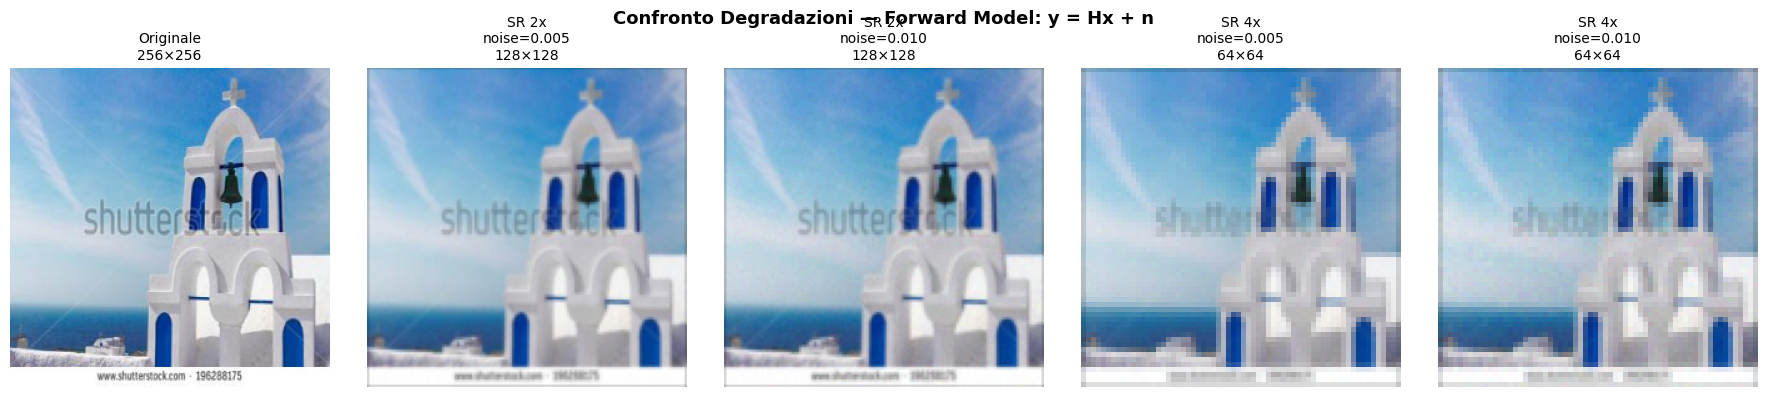

Plot salvato in data/degradation_examples.png


In [23]:
def get_sample_image(data_dir):
    """Carica un'immagine campione dal dataset o ne crea una sintetica."""
    test_dir = Path(data_dir) / 'test'
    files = sorted(test_dir.glob('*.png')) if test_dir.exists() else []
    if files:
        return Image.open(files[0]).convert('RGB'), files[0].name
    else:
        # Immagine sintetica di fallback
        arr = np.random.randint(60, 200, (256, 256, 3), dtype=np.uint8)
        # Aggiungi pattern per renderla più interessante
        for i in range(0, 256, 32):
            arr[i:i+4, :] = [180, 120, 60]
            arr[:, i:i+4] = [60, 120, 180]
        return Image.fromarray(arr), 'synthetic_sample.png'

img, img_name = get_sample_image(data_dir)
print(f'Immagine campione: {img_name} — size: {img.size}')

# Configurazioni di degradazione
configs = [
    {'sr_factor': 2, 'noise_std': 0.005, 'label': 'SR 2x\nnoise=0.005'},
    {'sr_factor': 2, 'noise_std': 0.010, 'label': 'SR 2x\nnoise=0.010'},
    {'sr_factor': 4, 'noise_std': 0.005, 'label': 'SR 4x\nnoise=0.005'},
    {'sr_factor': 4, 'noise_std': 0.010, 'label': 'SR 4x\nnoise=0.010'},
]

# Applica degradazioni
degraded_images = []
for cfg in configs:
    op = DegradationOperator(sr_factor=cfg['sr_factor'], noise_std=cfg['noise_std'], seed=42)
    deg_tensor = op(img)  # (C, H, W) in [0,1]
    deg_np = (deg_tensor.permute(1, 2, 0).numpy() * 255).clip(0, 255).astype(np.uint8)
    degraded_images.append(deg_np)

# Plot
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
fig.suptitle('Confronto Degradazioni — Forward Model: y = Hx + n', fontsize=13, fontweight='bold')

axes[0].imshow(np.array(img))
axes[0].set_title('Originale\n256×256', fontsize=10)
axes[0].axis('off')

for ax, deg_np, cfg in zip(axes[1:], degraded_images, configs):
    h, w = deg_np.shape[:2]
    ax.imshow(deg_np)
    ax.set_title(f"{cfg['label']}\n{w}×{h}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('../data/degradation_examples.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot salvato in data/degradation_examples.png')

## 5. Statistiche pixel del dataset

=== Statistiche Pixel (campione 100 immagini, range [0,1]) ===
  Media per canale — R: 0.4777, G: 0.4982, B: 0.5086
  Std per canale   — R: 0.2490, G: 0.2507, B: 0.2922


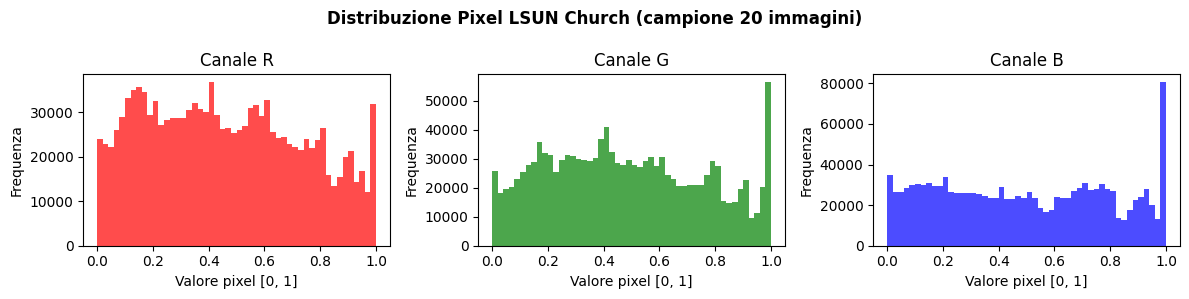

In [24]:
train_dir = data_dir / 'train'

if train_dir.exists():
    sample_files = sorted(train_dir.glob('*.png'))[:100]  # campione di 100
    
    channel_means = []
    channel_stds = []
    
    for f in sample_files:
        img_arr = np.array(Image.open(f).convert('RGB')).astype(np.float32) / 255.0
        channel_means.append(img_arr.mean(axis=(0, 1)))
        channel_stds.append(img_arr.std(axis=(0, 1)))
    
    mean = np.array(channel_means).mean(axis=0)
    std = np.array(channel_stds).mean(axis=0)
    
    print(f'=== Statistiche Pixel (campione {len(sample_files)} immagini, range [0,1]) ===')
    print(f'  Media per canale — R: {mean[0]:.4f}, G: {mean[1]:.4f}, B: {mean[2]:.4f}')
    print(f'  Std per canale   — R: {std[0]:.4f}, G: {std[1]:.4f}, B: {std[2]:.4f}')
    
    # Istogramma
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    colors = ['red', 'green', 'blue']
    channel_names = ['R', 'G', 'B']
    
    all_pixels = []
    for f in sample_files[:20]:  # usa 20 per l'istogramma
        all_pixels.append(np.array(Image.open(f).convert('RGB')).astype(np.float32) / 255.0)
    all_pixels = np.concatenate([p.reshape(-1, 3) for p in all_pixels], axis=0)
    
    for i, (ax, color, name) in enumerate(zip(axes, colors, channel_names)):
        ax.hist(all_pixels[:, i], bins=50, color=color, alpha=0.7, edgecolor='none')
        ax.set_title(f'Canale {name}')
        ax.set_xlabel('Valore pixel [0, 1]')
        ax.set_ylabel('Frequenza')
    
    plt.suptitle('Distribuzione Pixel LSUN Church (campione 20 immagini)', fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Dataset non trovato. Esegui prima: python src/dataset.py')
    print('Statistiche disponibili dopo il download.')

---
## Riepilogo

| Componente | Stato |
|:---|:---:|
| Normalizzazione `[0,1]` | ✅ |
| Downsampling 2x → 128×128 | ✅ |
| Downsampling 4x → 64×64 | ✅ |
| Rumore Gaussiano (0.005, 0.01) | ✅ |
| Split Train/Val/Test (80/10/10) | ✅ |